<a href="https://colab.research.google.com/github/KalebMwati/AI-Portfolio/blob/main/Stroke%20Prediction%20Logistic%20Regression%20FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression: Healthcare Stroke Prediction Model
**P5, M3, D2** - Pearson BTEC International Level 3 IT, Unit 21: Introduction to AI (Oshwal College). Scenario: Nairobi Smart Solutions Ltd.

One notebook covering the full pipeline in six steps: libraries, data, cleaning and imputation (M2), preprocessing and scaling, model training and refinement (P5/M3), metrics report, and charts and evaluation (D2).
Run from the `notebooks/` folder with the Kaggle CSV saved in `data/`. Target: `stroke` (1 = stroke). Success criteria (P3): recall (stroke) >= 0.70, precision (stroke) >= 0.15-0.20, ROC-AUC reported, accuracy secondary.

## Imports and configuration

In [ ]:
#Logistic regression Healthcare Stroke prediction Model
#P5, M3, D2
import numpy as np  # Handles numerical arrays, matrices, and math operations
import pandas as pd # Used for data manipulation, cleaning, and DataFrame analysis
import matplotlib.pyplot as plt # Creates basic static graphs, charts, and visualizations
import seaborn as sns # Draws advanced, polished statistical data visualizations
import os # Interacts with the operating system to manage files and folders
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict # Splits the data; cross-validation for the threshold search
from sklearn.preprocessing import StandardScaler, OneHotEncoder # Scales numerical values and encodes text categories into numbers
from sklearn.compose import ColumnTransformer # Applies different transformation steps to specific data columns
from sklearn.linear_model import LogisticRegression # The machine learning model used to predict binary categories
from sklearn.pipeline import Pipeline # Chains preprocessing and the model so scaling is fitted on training data only
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             precision_score, recall_score, accuracy_score, f1_score, roc_curve)  # Metrics to evaluate model performance

RANDOM_STATE = 42
CSV_PATH = "../data/healthcare-dataset-stroke-data.csv"   # run the notebook from the notebooks/ folder
OUT_DIR = "../script_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

## Step 0: Libraries to be used

In [ ]:
print("Step 0: libraries loaded")

Step 0: libraries loaded


## Step 1: Fetching the Data from Kaggle
The CSV is downloaded manually from Kaggle and loaded with Pandas, then audited.

In [ ]:
# Download the CSV manually from
# https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset
# and save it as data/healthcare-dataset-stroke-data.csv (or pass its path as the first argument).
print("\nStep 1: loading data")
raw = pd.read_csv(CSV_PATH)
print("Rows, columns:", raw.shape)
print("Missing values per column:\n", raw.isna().sum()[raw.isna().sum() > 0].to_string())
print(f"Missing BMI: {raw['bmi'].isna().sum()} ({raw['bmi'].isna().mean() * 100:.2f}%)")
print(f"Stroke cases: {raw['stroke'].sum()} ({raw['stroke'].mean() * 100:.2f}%)")


Step 1: loading data
Rows, columns: (5110, 12)
Missing values per column:
 bmi    201
Missing BMI: 201 (3.93%)
Stroke cases: 249 (4.87%)


In [ ]:
raw.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [ ]:
print("Total rows:", len(raw), "| duplicate rows:", int(raw.duplicated().sum()), "| duplicate ids:", int(raw["id"].duplicated().sum()))
miss = raw.isna().sum()
pd.DataFrame({"missing": miss, "missing_%": (miss / len(raw) * 100).round(2)})[miss > 0]

Total rows: 5110 | duplicate rows: 0 | duplicate ids: 0


,missing,missing_%
bmi,201,3.93


        count  percent
stroke                
0        4861    95.13
1         249     4.87

Majority-class (always predict 'no stroke') accuracy: 0.9513


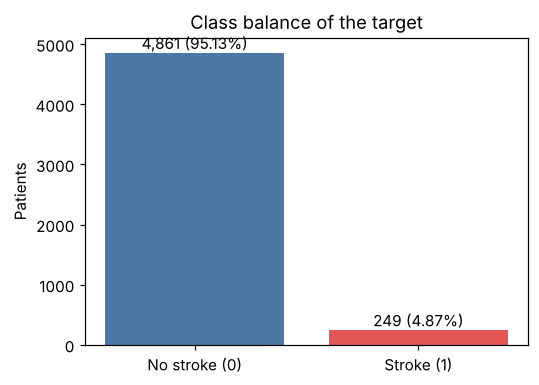

In [ ]:
vc = raw["stroke"].value_counts().sort_index()
print(pd.DataFrame({"count": vc, "percent": (vc / len(raw) * 100).round(2)}))
print("\nMajority-class (always predict 'no stroke') accuracy:", round(vc.max() / len(raw), 4))
fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["No stroke (0)", "Stroke (1)"], vc.values, color=["#4C78A8", "#E45756"])
ax.bar_label(bars, labels=[f"{v:,} ({v/len(raw)*100:.2f}%)" for v in vc.values])
ax.set_ylabel("Patients"); ax.set_title("Class balance of the target")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "01_class_balance.png"), dpi=150)

In [ ]:
for c in ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]:
    print(raw[c].value_counts().to_string(), "\n")
raw[["age", "avg_glucose_level", "bmi"]].describe().round(2)

gender
Female    2994
Male      2115
Other        1 

ever_married
Yes    3353
No     1757 

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22 

Residence_type
Urban    2596
Rural    2514 

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789 



,age,avg_glucose_level,bmi
count,5110.00,5110.00,4909.00
mean,43.23,106.15,28.89
std,22.61,45.28,7.85
min,0.08,55.12,10.30
25%,25.00,77.24,23.50
50%,45.00,91.88,28.10
75%,61.00,114.09,33.10
max,82.00,271.74,97.60


In [ ]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
print({c: iqr_outliers(raw[c].dropna()) for c in ["age", "avg_glucose_level", "bmi"]})
print("Smoking 'Unknown':", int((raw.smoking_status == "Unknown").sum()), f"({(raw.smoking_status == 'Unknown').mean()*100:.1f}%)")

{'age': 0, 'avg_glucose_level': 627, 'bmi': 110}
Smoking 'Unknown': 1544 (30.2%)


In [ ]:
bins = [0, 18, 30, 45, 60, 75, 200]; labels = ["<18", "18-29", "30-44", "45-59", "60-74", "75+"]
raw_band = pd.cut(raw["age"], bins=bins, labels=labels, right=False)
miss_by_band = raw.groupby(raw_band, observed=True)["bmi"].apply(lambda s: s.isna().mean() * 100).round(2)
stroke_by_band = raw.groupby(raw_band, observed=True)["stroke"].mean().mul(100).round(2)
print(pd.DataFrame({"bmi_missing_%": miss_by_band, "stroke_rate_%": stroke_by_band}))
m = raw["bmi"].isna()
print("\nStroke rate (%) among patients WITH missing BMI:", round(raw.loc[m, "stroke"].mean() * 100, 2), "| with BMI present:", round(raw.loc[~m, "stroke"].mean() * 100, 2))
print("Stroke cases among the", int(m.sum()), "missing-BMI rows:", int(raw.loc[m, "stroke"].sum()),
      f"= {raw.loc[m, 'stroke'].sum() / raw['stroke'].sum() * 100:.1f}% of all stroke cases (dropping these rows would discard them)")

       bmi_missing_%  stroke_rate_%
age                                
<18             2.34           0.23
18-29           1.82           0.00
30-44           3.54           0.79
45-59           3.50           4.83
60-74           6.06           9.21
75+             7.53          19.69

Stroke rate (%) among patients WITH missing BMI: 19.9 | with BMI present: 4.26
Stroke cases among the 201 missing-BMI rows: 40 = 16.1% of all stroke cases (dropping these rows would discard them)


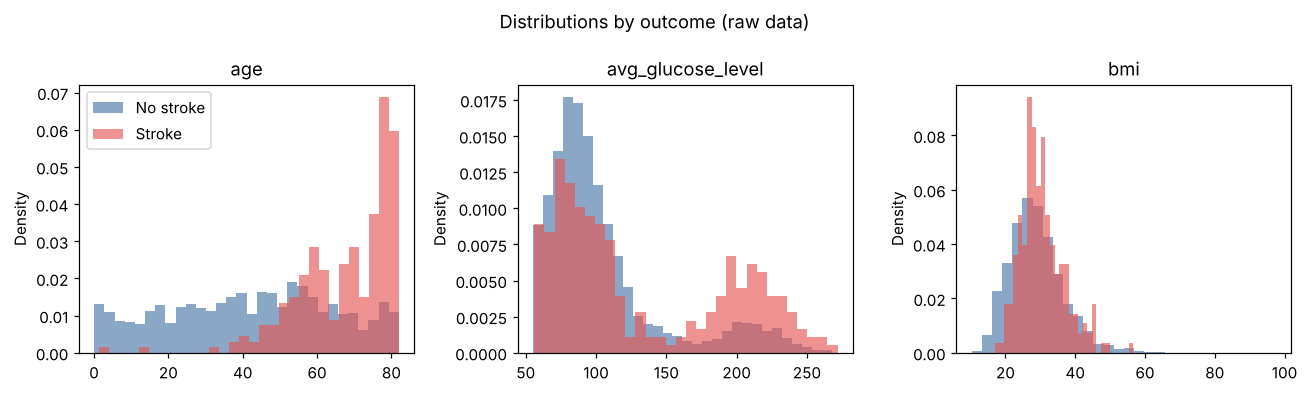

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    for label, colour, name in [(0, "#4C78A8", "No stroke"), (1, "#E45756", "Stroke")]:
        ax.hist(raw.loc[raw.stroke == label, col].dropna(), bins=30, alpha=.65, density=True, color=colour, label=name)
    ax.set_title(col); ax.set_ylabel("Density")
axes[0].legend(); fig.suptitle("Distributions by outcome (raw data)"); fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "02_distributions_by_stroke.png"), dpi=150)

              patients  stroke_cases  stroke_rate_pct
hypertension                                         
0                 4612           183             3.97
1                  498            66            13.25 

               patients  stroke_cases  stroke_rate_pct
heart_disease                                         
0                  4834           202             4.18
1                   276            47            17.03 



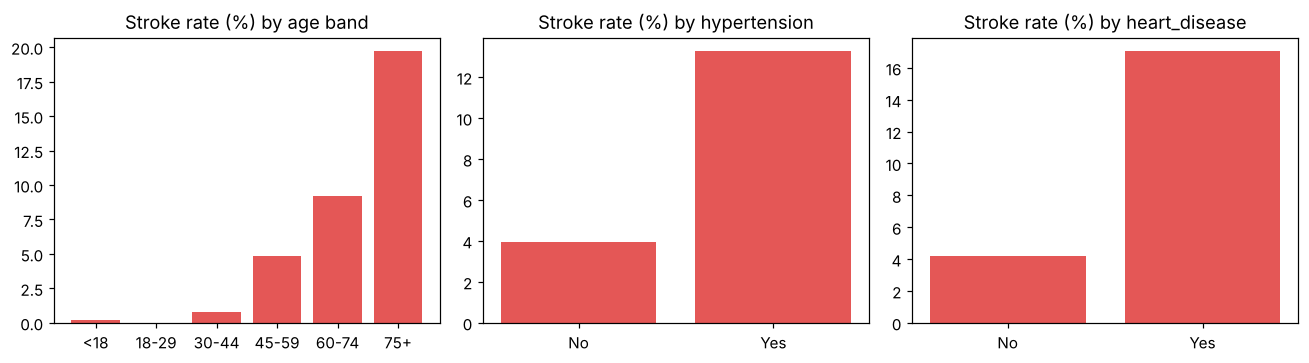

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].bar(stroke_by_band.index.astype(str), stroke_by_band.values, color="#E45756"); axes[0].set_title("Stroke rate (%) by age band")
for ax, col in zip(axes[1:], ["hypertension", "heart_disease"]):
    r = raw.groupby(col)["stroke"].mean() * 100
    ax.bar(["No", "Yes"], r.values, color="#E45756"); ax.set_title(f"Stroke rate (%) by {col}")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "03_stroke_rate_by_factor.png"), dpi=150)
for col in ["hypertension", "heart_disease"]:
    g = raw.groupby(col)["stroke"].agg(patients="size", stroke_cases="sum", stroke_rate_pct=lambda s: round(s.mean() * 100, 2))
    print(g, "\n")

## Step 2: Refinement and IMPUTATION (M2)
Drop `id`, remove the single `gender = 'Other'` row, split 80/20 (stratified), then fill missing BMI with age-band medians calculated on the training set only.

In [ ]:
print("\nStep 2: cleaning and imputation")
df = raw.drop(columns=["id"])                         # identifier, no predictive meaning
df = df[df["gender"] != "Other"].reset_index(drop=True)  # single record, cannot be learned or evaluated
X = df.drop(columns="stroke")
y = df["stroke"]
# Stratified 80/20 split BEFORE imputation so no test information leaks into the filled values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

AGE_BINS = [0, 18, 30, 45, 60, 75, 200]
AGE_LABELS = ["<18", "18-29", "30-44", "45-59", "60-74", "75+"]
def age_band(age):
    return pd.cut(age, bins=AGE_BINS, labels=AGE_LABELS, right=False)

# Age-band median BMI, calculated on the TRAINING set only, applied to both sets
band_median = X_train.groupby(age_band(X_train["age"]), observed=False)["bmi"].median().fillna(X_train["bmi"].median())
X_train, X_test = X_train.copy(), X_test.copy()
X_train["bmi"] = X_train["bmi"].fillna(age_band(X_train["age"]).map(band_median).astype(float))
X_test["bmi"] = X_test["bmi"].fillna(age_band(X_test["age"]).map(band_median).astype(float))
print("Training medians by age band:\n", band_median.round(2).to_string())
print("Missing BMI after imputation: train", int(X_train["bmi"].isna().sum()), "| test", int(X_test["bmi"].isna().sum()))
print(f"Train: {len(y_train)} rows, {int(y_train.sum())} strokes | Test: {len(y_test)} rows, {int(y_test.sum())} strokes")


Step 2: cleaning and imputation
Training medians by age band:
 age
<18      19.90
18-29    26.20
30-44    30.00
45-59    30.30
60-74    30.05
75+      28.10
Missing BMI after imputation: train 0 | test 0
Train: 4087 rows, 199 strokes | Test: 1022 rows, 50 strokes


In [ ]:
print("Rows before cleaning:", len(raw), "| 'Other' gender rows removed:", int((raw.gender == "Other").sum()), "| rows after:", len(df))
print("Stroke cases after cleaning:", int(df.stroke.sum()), f"({df.stroke.mean()*100:.2f}%)")

Rows before cleaning: 5110 | 'Other' gender rows removed: 1 | rows after: 5109
Stroke cases after cleaning: 249 (4.87%)


In [ ]:
bmi_missing_before = {"train": int(df.loc[X_train.index, "bmi"].isna().sum()), "test": int(df.loc[X_test.index, "bmi"].isna().sum())}
print("Missing BMI filled by imputation:", bmi_missing_before)
pd.DataFrame({"rows": [len(y_train), len(y_test)], "stroke_cases": [int(y_train.sum()), int(y_test.sum())],
              "stroke_%": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]}, index=["train", "test"])

Missing BMI filled by imputation: {'train': 163, 'test': 38}


,rows,stroke_cases,stroke_%
train,4087,199,4.87
test,1022,50,4.89


## Step 3: PreProcessing and Structural Scaling
Binary and multi-category text columns are one-hot encoded and the numeric columns are standardised, with both steps fitted on the training set only.

In [ ]:
print("\nStep 3: encoding and scaling")
numeric_cols = ["age", "avg_glucose_level", "bmi"]
categorical_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
# Binary flags (hypertension, heart_disease) already 0/1 and are passed through unchanged.
# Scaler and encoder are fitted on the training data only, inside the pipeline.
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), numeric_cols),
                  ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)],
    remainder="passthrough")

def make_model(class_weight=None):
    return Pipeline([("prep", preprocessor), ("clf", LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=RANDOM_STATE))])


Step 3: encoding and scaling


In [ ]:
from sklearn.base import clone
prep_demo = clone(preprocessor).set_params(cat__sparse_output=False).set_output(transform="pandas")   # dense output only so the columns can be displayed
Xtr_enc = prep_demo.fit_transform(X_train)          # fitted on the training set only
Xte_enc = prep_demo.transform(X_test)
print("Encoded feature columns:", len(Xtr_enc.columns))
print(list(Xtr_enc.columns))
print("Non-numeric columns remaining:", list(Xtr_enc.select_dtypes(exclude="number").columns))
Xtr_enc.head()

Encoded feature columns: 15
['num__age', 'num__avg_glucose_level', 'num__bmi', 'cat__gender_Male', 'cat__ever_married_Yes', 'cat__work_type_Never_worked', 'cat__work_type_Private', 'cat__work_type_Self-employed', 'cat__work_type_children', 'cat__Residence_type_Urban', 'cat__smoking_status_formerly smoked', 'cat__smoking_status_never smoked', 'cat__smoking_status_smokes', 'remainder__hypertension', 'remainder__heart_disease']
Non-numeric columns remaining: []


,num__age,num__avg_glucose_level,num__bmi,cat__gender_Male,cat__ever_married_Yes,cat__work_type_Never_worked,cat__work_type_Private,cat__work_type_Self-employed,cat__work_type_children,cat__Residence_type_Urban,cat__smoking_status_formerly smoked,cat__smoking_status_never smoked,cat__smoking_status_smokes,remainder__hypertension,remainder__heart_disease
845,0.209397,-0.821221,0.545581,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0,0
3744,-0.629845,-0.485884,-0.988298,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0,0
4183,-0.364822,0.302317,-0.769172,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,0
3409,-0.232310,0.062342,0.494022,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,0
284,-1.292405,-0.527297,0.352235,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0


In [ ]:
nc = ["num__age", "num__avg_glucose_level", "num__bmi"]
pd.DataFrame({"train_mean": Xtr_enc[nc].mean().round(3), "train_std": Xtr_enc[nc].std().round(3),
              "test_mean": Xte_enc[nc].mean().round(3), "test_std": Xte_enc[nc].std().round(3)})

,train_mean,train_std,test_mean,test_std
num__age,-0.0,1.0,-0.006,0.994
num__avg_glucose_level,0.0,1.0,0.027,1.067
num__bmi,0.0,1.0,0.007,0.977


In [ ]:
after = pd.concat([X_train, X_test])
comparison = pd.DataFrame({
    "Before (raw)": [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum()), int(raw.bmi.isna().sum()), round(raw.bmi.mean(), 2),
                     round(raw.bmi.median(), 2), round(raw.bmi.std(), 2), int((raw.gender == "Other").sum()),
                     int(raw.select_dtypes(exclude="number").shape[1]), "no"],
    "After (cleaned)": [after.shape[0], Xtr_enc.shape[1] + 1, int(after.isna().sum().sum()), int(after.bmi.isna().sum()), round(after.bmi.mean(), 2),
                        round(after.bmi.median(), 2), round(after.bmi.std(), 2), 0, int(Xtr_enc.select_dtypes(exclude="number").shape[1]), "yes (train mean/std)"]},
    index=["Rows", "Columns (incl. target)", "Total missing cells", "Missing BMI", "BMI mean", "BMI median", "BMI std",
           "gender='Other' rows", "Non-numeric feature columns", "Numeric features scaled"])
comparison

,Before (raw),After (cleaned)
Rows,5110,5109
Columns (incl. target),12,16
Total missing cells,201,0
Missing BMI,201,0
BMI mean,28.89,28.88
BMI median,28.1,28.2
BMI std,7.85,7.72
gender='Other' rows,1,0
Non-numeric feature columns,5,0
Numeric features scaled,no,yes (train mean/std)


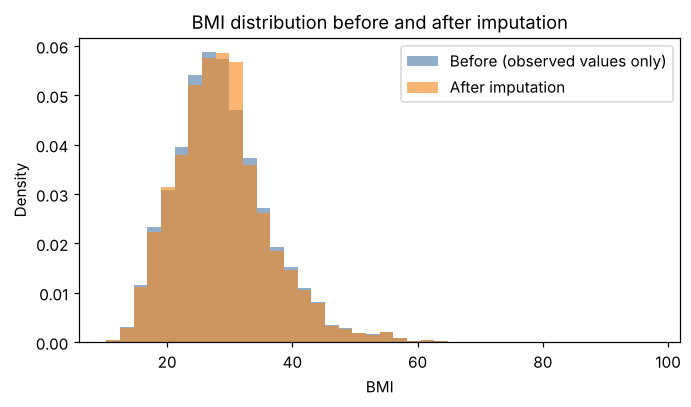

In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.hist(raw.bmi.dropna(), bins=40, alpha=.6, density=True, label="Before (observed values only)", color="#4C78A8")
ax.hist(after.bmi, bins=40, alpha=.6, density=True, label="After imputation", color="#F58518")
ax.set_xlabel("BMI"); ax.set_ylabel("Density"); ax.set_title("BMI distribution before and after imputation"); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "04_bmi_before_after.png"), dpi=150)

## Step 4: Model Training and Refinement comparisions(P5/M3)
Baseline Logistic Regression, then `class_weight='balanced'`, then a decision-threshold search (maximise precision while recall >= 0.70) chosen on out-of-fold training predictions.

In [ ]:
print("Train:", X_train.shape, "stroke cases:", int(y_train.sum()), "| Test:", X_test.shape, "stroke cases:", int(y_test.sum()))
print("Missing values in features:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))

Train: (4087, 10) stroke cases: 199 | Test: (1022, 10) stroke cases: 50
Missing values in features: 0


In [ ]:
print("\nStep 4: training")
def evaluate(name, y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"model": name, "threshold": round(float(threshold), 2), "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred, zero_division=0), "roc_auc": roc_auc_score(y_true, proba),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


Step 4: training


In [ ]:
# 4a. Baseline (no imbalance handling, threshold 0.5)
baseline = make_model().fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
print('Baseline trained on', len(y_train), 'rows; probabilities predicted for', len(p_base), 'test patients')

Baseline trained on 4087 rows; probabilities predicted for 1022 test patients


In [ ]:
def show(rows):
    return pd.DataFrame(rows).set_index("model").round({"accuracy": 4, "precision": 4, "recall": 4, "f1": 4, "roc_auc": 4})
r_base = evaluate("Baseline", y_test, p_base, 0.5)
print("Predicted stroke cases at 0.5:", int((p_base >= 0.5).sum()), "of", len(y_test), "| actual stroke cases:", int(y_test.sum()))
print("Highest predicted stroke probability in the test set:", round(float(p_base.max()), 3))
print("Always-'no stroke' accuracy for comparison:", round(1 - y_test.mean(), 4))
print(pd.DataFrame(confusion_matrix(y_test, (p_base >= 0.5).astype(int)), index=["actual no stroke", "actual stroke"], columns=["pred no stroke", "pred stroke"]))
show([r_base])

Predicted stroke cases at 0.5: 1 of 1022 | actual stroke cases: 50
Highest predicted stroke probability in the test set: 0.533
Always-'no stroke' accuracy for comparison: 0.9511
                  pred no stroke  pred stroke
actual no stroke             972            0
actual stroke                 49            1


,threshold,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
Baseline,0.5,0.9521,1.0,0.02,0.0392,0.8392,1,0,49,972


In [ ]:
# 4b. class_weight="balanced"
balanced = make_model("balanced").fit(X_train, y_train)
p_bal = balanced.predict_proba(X_test)[:, 1]
print('Class-weighted model trained; class weights (balanced) =', dict(zip([0, 1], np.round(len(y_train) / (2 * np.bincount(y_train)), 3))))

Class-weighted model trained; class weights (balanced) = {0: np.float64(0.526), 1: np.float64(10.269)}


In [ ]:
r_bal = evaluate("Balanced (thr 0.5)", y_test, p_bal, 0.5)
show([r_base, r_bal])

,threshold,accuracy,precision,recall,f1,roc_auc,TP,FP,FN,TN
model,,,,,,,,,,
Baseline,0.5,0.9521,1.0000,0.02,0.0392,0.8392,1,0,49,972
Balanced (thr 0.5),0.5,0.7378,0.1342,0.80,0.2299,0.8394,40,258,10,714


In [ ]:
# 4c. Threshold search: maximise precision while recall >= 0.70, chosen on out-of-fold TRAINING predictions
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(make_model("balanced"), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
rows = []
for t in np.round(np.arange(0.05, 0.96, 0.01), 2):
    pr = (oof >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_train, pr, zero_division=0), "recall": recall_score(y_train, pr)})
sweep = pd.DataFrame(rows)
eligible = sweep[sweep["recall"] >= 0.70]
best = eligible.loc[eligible["precision"].idxmax()]
THRESH = float(best["threshold"])
print(f"Thresholds with out-of-fold recall >= 0.70: {len(eligible)} of {len(sweep)} | chosen: {THRESH} "
      f"(precision {best['precision']:.4f}, recall {best['recall']:.4f})")

results = pd.DataFrame([evaluate("Baseline", y_test, p_base, 0.5),
                        evaluate("Balanced (thr 0.5)", y_test, p_bal, 0.5),
                        evaluate(f"Balanced + thr {THRESH}", y_test, p_bal, THRESH)]).set_index("model")

Thresholds with out-of-fold recall >= 0.70: 54 of 91 | chosen: 0.58 (precision 0.1442, recall 0.7085)


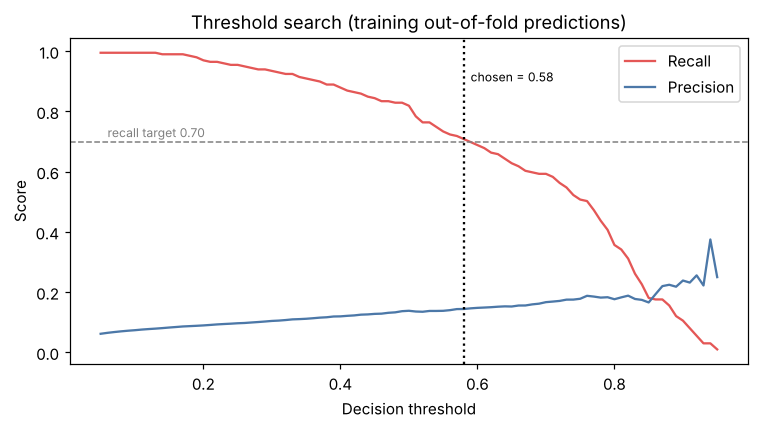

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep.threshold, sweep.recall, label="Recall", color="#E45756"); ax.plot(sweep.threshold, sweep.precision, label="Precision", color="#4C78A8")
ax.axhline(0.70, ls="--", color="grey", lw=1); ax.text(0.06, 0.715, "recall target 0.70", color="grey", fontsize=8)
ax.axvline(THRESH, ls=":", color="black"); ax.text(THRESH + 0.01, 0.9, f"chosen = {THRESH}", fontsize=8)
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score"); ax.set_title("Threshold search (training out-of-fold predictions)"); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "05_threshold_search.png"), dpi=150)

## Step 5: Output Metrics Report

In [ ]:
print("\nStep 5: metrics report (held-out test set)")
print(results.round(4).to_string())


Step 5: metrics report (held-out test set)
                     threshold  accuracy  precision  recall      f1  roc_auc  TP   FP  FN   TN
model                                                                                         
Baseline                  0.50    0.9521     1.0000    0.02  0.0392   0.8392   1    0  49  972
Balanced (thr 0.5)        0.50    0.7378     0.1342    0.80  0.2299   0.8394  40  258  10  714
Balanced + thr 0.58       0.58    0.7926     0.1653    0.80  0.2740   0.8394  40  202  10  770


In [ ]:
pred_final = (p_bal >= THRESH).astype(int)
print("\nClassification report, final model:\n", classification_report(y_test, pred_final, target_names=["No stroke", "Stroke"], digits=4))
print("Confusion matrix (rows = actual, columns = predicted):\n", confusion_matrix(y_test, pred_final))
final = results.iloc[2]
print("\nSuccess criteria:")
print(f"  recall >= 0.70      : {final['recall']:.4f} -> {'MET' if final['recall'] >= 0.70 else 'NOT MET'}")
print(f"  precision >= 0.15   : {final['precision']:.4f} -> {'MET' if final['precision'] >= 0.15 else 'NOT MET'}")
print(f"  precision >= 0.20   : {'MET' if final['precision'] >= 0.20 else 'NOT MET'}")
print(f"  ROC-AUC (reported)  : {final['roc_auc']:.4f}")
print(f"  accuracy (secondary): {final['accuracy']:.4f}")
results.round(4).to_csv(os.path.join(OUT_DIR, "metrics_summary.csv"))


Classification report, final model:
               precision    recall  f1-score   support

   No stroke     0.9872    0.7922    0.8790       972
      Stroke     0.1653    0.8000    0.2740        50

    accuracy                         0.7926      1022
   macro avg     0.5762    0.7961    0.5765      1022
weighted avg     0.9470    0.7926    0.8494      1022

Confusion matrix (rows = actual, columns = predicted):
 [[770 202]
 [ 10  40]]

Success criteria:
  recall >= 0.70      : 0.8000 -> MET
  precision >= 0.15   : 0.1653 -> MET
  precision >= 0.20   : NOT MET
  ROC-AUC (reported)  : 0.8394
  accuracy (secondary): 0.7926


## Step 6: Chart Generation and Evaluation


Step 6: charts


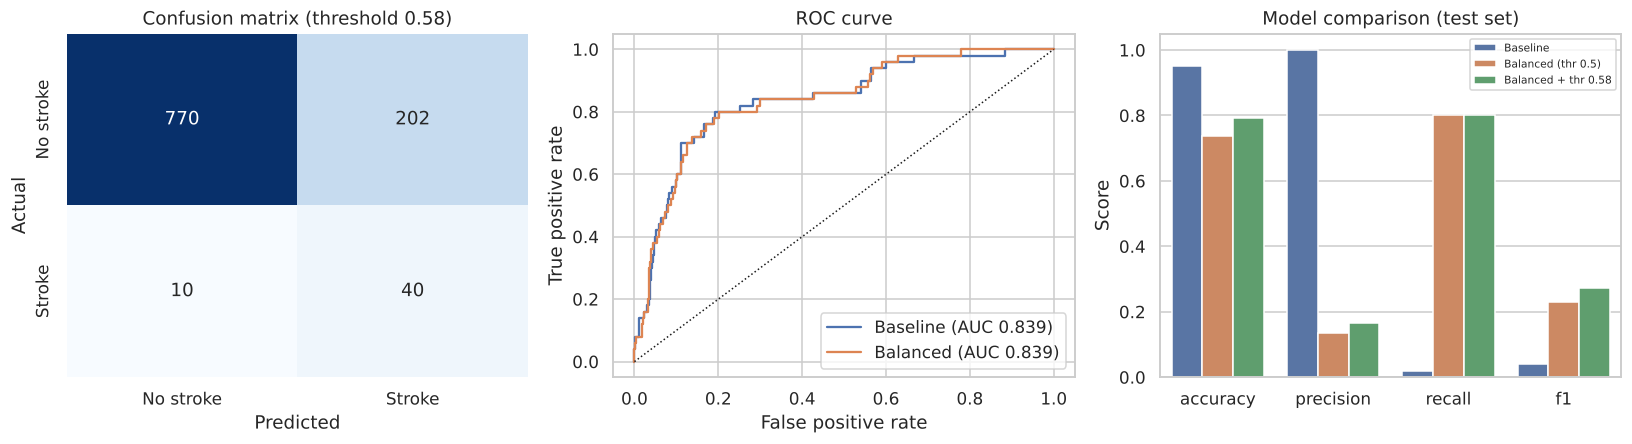

In [ ]:
print("\nStep 6: charts")
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.heatmap(confusion_matrix(y_test, pred_final), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["No stroke", "Stroke"], yticklabels=["No stroke", "Stroke"])
axes[0].set(title=f"Confusion matrix (threshold {THRESH})", xlabel="Predicted", ylabel="Actual")
for name, p in [("Baseline", p_base), ("Balanced", p_bal)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k:", lw=1); axes[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate"); axes[1].legend()
melted = results.reset_index().melt(id_vars="model", value_vars=["accuracy", "precision", "recall", "f1"])
sns.barplot(data=melted, x="variable", y="value", hue="model", ax=axes[2])
axes[2].set(title="Model comparison (test set)", xlabel="", ylabel="Score", ylim=(0, 1.05)); axes[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "evaluation_charts.png"), dpi=150)

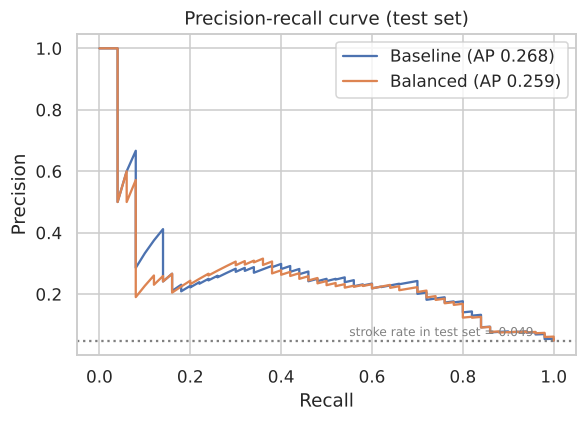

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
fig, ax = plt.subplots(figsize=(5.5, 4))
for name, p in [("Baseline", p_base), ("Balanced", p_bal)]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls=":", color="grey"); ax.text(0.55, y_test.mean() + 0.015, f"stroke rate in test set = {y_test.mean():.3f}", fontsize=8, color="grey")
ax.set(title="Precision-recall curve (test set)", xlabel="Recall", ylabel="Precision"); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "06_precision_recall.png"), dpi=150)

Saved charts and metrics to ../script_outputs/


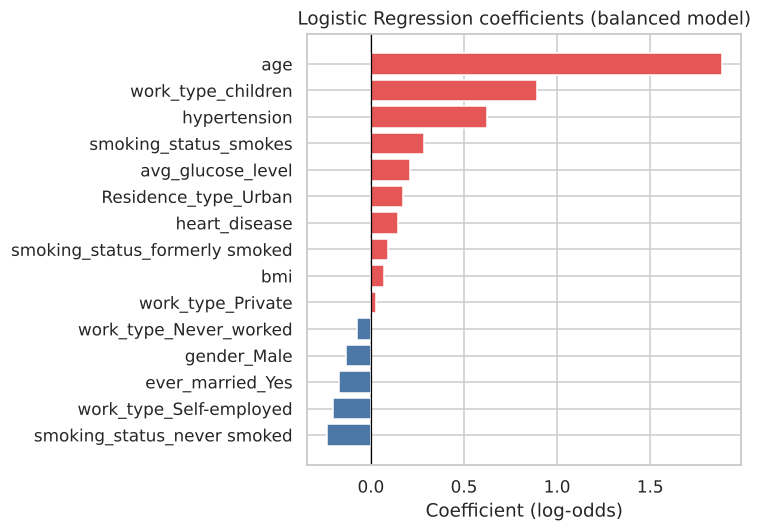

In [ ]:
feature_names = [n.split("__")[1] for n in balanced.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(balanced.named_steps["clf"].coef_[0], index=feature_names).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(coef.index, coef.values, color=["#E45756" if v > 0 else "#4C78A8" for v in coef.values])
ax.axvline(0, color="black", lw=.8); ax.set(title="Logistic Regression coefficients (balanced model)", xlabel="Coefficient (log-odds)")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "coefficients.png"), dpi=150)
print("Saved charts and metrics to", OUT_DIR + "/")

In [ ]:
coef_tbl = pd.DataFrame({"coefficient": coef, "odds_ratio": np.exp(coef)}).sort_values("coefficient", key=abs, ascending=False)
print("Intercept:", round(float(balanced.named_steps["clf"].intercept_[0]), 3))
coef_tbl.round(3)

Intercept: -1.234


,coefficient,odds_ratio
age,1.884,6.579
work_type_children,0.889,2.434
hypertension,0.623,1.865
smoking_status_smokes,0.286,1.331
smoking_status_never smoked,-0.236,0.789
avg_glucose_level,0.210,1.233
work_type_Self-employed,-0.205,0.815
Residence_type_Urban,0.173,1.189
ever_married_Yes,-0.170,0.844
heart_disease,0.145,1.156


## Evaluation: how reliable is the result? (D2)
The test set contains only 50 stroke cases, so recall moves in steps of 0.02. Two checks: a bootstrap of the test set, and the full procedure repeated over ten different splits.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE); yt = y_test.to_numpy(); pred = (p_bal >= THRESH).astype(int)
rec, prec, auc = [], [], []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0: continue
    rec.append(recall_score(yt[idx], pred[idx])); prec.append(precision_score(yt[idx], pred[idx], zero_division=0)); auc.append(roc_auc_score(yt[idx], p_bal[idx]))
ci = lambda a: tuple(np.percentile(a, [2.5, 97.5]).round(3))
pd.DataFrame({"estimate": [final["recall"], final["precision"], final["roc_auc"]],
              "95% CI low": [ci(rec)[0], ci(prec)[0], ci(auc)[0]], "95% CI high": [ci(rec)[1], ci(prec)[1], ci(auc)[1]]},
             index=["recall", "precision", "roc_auc"]).round(3)

,estimate,95% CI low,95% CI high
recall,0.800,0.686,0.911
precision,0.165,0.121,0.212
roc_auc,0.839,0.780,0.894


In [ ]:
# Full procedure repeated on 10 different stratified splits: split -> impute (train medians) -> OOF threshold search -> test
out = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    Xa, Xb = Xa.copy(), Xb.copy()
    med = Xa.groupby(age_band(Xa["age"]), observed=False)["bmi"].median().fillna(Xa["bmi"].median())
    Xa["bmi"] = Xa["bmi"].fillna(age_band(Xa["age"]).map(med).astype(float)); Xb["bmi"] = Xb["bmi"].fillna(age_band(Xb["age"]).map(med).astype(float))
    o = cross_val_predict(make_model("balanced"), Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    cand = [(t, precision_score(ya, o >= t, zero_division=0), recall_score(ya, o >= t)) for t in np.round(np.arange(0.05, 0.96, 0.01), 2)]
    ok = [c for c in cand if c[2] >= 0.70]; t = max(ok, key=lambda c: c[1])[0] if ok else 0.5
    pb = make_model("balanced").fit(Xa, ya).predict_proba(Xb)[:, 1]
    out.append({"seed": seed, "threshold": t, "recall": recall_score(yb, pb >= t), "precision": precision_score(yb, pb >= t, zero_division=0), "roc_auc": roc_auc_score(yb, pb)})
rep = pd.DataFrame(out).set_index("seed")
print(rep.round(3).to_string()); print("\nMean:"); print(rep.mean().round(3).to_string())
print("Splits with recall below 0.70:", int((rep.recall < 0.70).sum()), "of", len(rep), "| precision range:", round(rep.precision.min(), 3), "to", round(rep.precision.max(), 3))

      threshold  recall  precision  roc_auc
seed                                       
0          0.61    0.60      0.130    0.805
1          0.60    0.66      0.151    0.827
2          0.59    0.72      0.143    0.861
3          0.59    0.72      0.133    0.792
4          0.58    0.86      0.162    0.873
5          0.60    0.68      0.148    0.836
6          0.58    0.80      0.156    0.833
7          0.60    0.78      0.167    0.881
8          0.61    0.60      0.153    0.828
9          0.59    0.66      0.133    0.827

Mean:
threshold    0.595
recall       0.708
precision    0.148
roc_auc      0.836
Splits with recall below 0.70: 5 of 10 | precision range: 0.13 to 0.167
